# Análise Epidemiológica e Distribuição de Vacinas em Destaque

**Projeto:** PyAnalytics — UFSC Araranguá

**Autoras:** Beatriz Goulart e Esther de Oliveira  

**Arquivo de Origem:** `vacinas_analitico.csv`  

---

## Contexto e Objetivos

A análise dos registros de vacinação permite identificar quais imunizantes apresentam maior ou menor participação na base e compreender como essa distribuição se comporta de acordo com diferentes dimensões, como período, estratégia, dose e território.

Esta análise busca destacar os principais imunizantes presentes na base e organizar sua distribuição de forma que facilite a interpretação dos registros de vacinação, permitindo:

1. Identificar quais vacinas apresentam maior volume de aplicações registradas.
2. Comparar a participação dos imunizantes por diferentes medidas e recortes.
3. Verificar se a posição das vacinas se modifica conforme o período e a estratégia.
4. Avaliar se os registros estão concentrados em poucos imunizantes ou distribuídos de forma mais equilibrada.
5. Preservar diferenças entre apresentações, estratégias e doses para evitar agrupamentos inadequados.

## 1. Bibliotecas e configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 2. Carregamento da base

In [2]:
from pathlib import Path

caminhos = [
    Path("../../data/processed/vacinas_analitico.csv"),
    Path("../data/processed/vacinas_analitico.csv"),
    Path("data/processed/vacinas_analitico.csv"),
    Path("vacinas_analitico.csv")
]

file_path = next((caminho for caminho in caminhos if caminho.exists()), None)

if file_path is None:
    raise FileNotFoundError("O arquivo não foi encontrado.")

df = pd.read_csv(file_path)

print(f"Arquivo utilizado: {file_path}")
display(df.head())

Arquivo utilizado: ..\..\data\processed\vacinas_analitico.csv


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## 3. Estrutura da base

In [3]:
print(f"Registros: {df.shape[0]:,}".replace(",", "."))
print(f"Colunas: {df.shape[1]}")

display(pd.DataFrame({
    "Coluna": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Valores ausentes": df.isna().sum().values,
    "Valores distintos": [df[col].nunique(dropna=True) for col in df.columns]
}))

display(df.head())

Registros: 30.883
Colunas: 12


,Coluna,Tipo,Valores ausentes,Valores distintos
0,nome_do_bairro,str,0,15
1,nome_da_vacina,str,0,41
2,codigo_da_vacina,int64,0,33
3,estrategia,str,0,12
4,codigo_da_estrategia,int64,0,9
5,dose,str,9,27
6,codigo_da_dose,float64,9,23
7,vacina_estrategia_e_dose,str,0,163
8,lote,str,0,271
9,validade_do_lote,str,0,101


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## 4. Qualidade dos dados

In [4]:
qualidade = pd.DataFrame({
    "Indicador": [
        "Registros",
        "Colunas",
        "Registros duplicados",
        "Células ausentes"
    ],
    "Valor": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df.isna().sum().sum())
    ]
})

display(qualidade)

ausentes = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename_axis("Coluna")
    .reset_index(name="Valores ausentes")
)

display(ausentes.head(15))

,Indicador,Valor
0,Registros,30883
1,Colunas,12
2,Registros duplicados,23209
3,Células ausentes,1738


,Coluna,Valores ausentes
0,origem,860
1,data_da_aplicacao,860
2,codigo_da_dose,9
3,dose,9
4,estrategia,0
5,codigo_da_vacina,0
6,nome_da_vacina,0
7,nome_do_bairro,0
8,vacina_estrategia_e_dose,0
9,codigo_da_estrategia,0


## 5. Tratamento da data

In [5]:
df["data_da_aplicacao"] = pd.to_datetime(
    df["data_da_aplicacao"],
    dayfirst=True,
    errors="coerce"
)

df["ano"] = df["data_da_aplicacao"].dt.year
df["mes"] = df["data_da_aplicacao"].dt.to_period("M").astype("string")

print("Período inicial:", df["data_da_aplicacao"].min())
print("Período final:", df["data_da_aplicacao"].max())
print("Datas inválidas:", int(df["data_da_aplicacao"].isna().sum()))

display(
    df[["data_da_aplicacao", "ano", "mes"]]
    .head()
)

Período inicial: 2026-02-01 00:00:00
Período final: 2026-06-30 00:00:00
Datas inválidas: 860


,data_da_aplicacao,ano,mes
0,2026-04-02,2026.0,2026-04
1,2026-04-02,2026.0,2026-04
2,2026-04-02,2026.0,2026-04
3,2026-04-02,2026.0,2026-04
4,2026-04-02,2026.0,2026-04


## 6. Distribuição dos imunizantes

In [6]:
vacinas = (
    df["nome_da_vacina"]
    .value_counts(dropna=False)
    .rename_axis("Vacina")
    .reset_index(name="Aplicações")
)

vacinas["Percentual (%)"] = vacinas["Aplicações"] / len(df) * 100

display(vacinas.head(15))

,Vacina,Aplicações,Percentual (%)
0,Vacina influenza trivalente,15809,51.189975
1,Vacina difteria e tétano adulto,1608,5.206748
2,Vacina hepatite B,1274,4.125247
3,Vacina dengue (atenuada),1244,4.028106
4,Vacina polio injetável (inativada poliomielite),1197,3.875919
5,Vacina febre amarela,930,3.011365
6,"Vacina sarampo, caxumba, rubéola",924,2.991937
7,Vacina penta (DTP/HepB/Hib),829,2.684325
8,Vacina pneumo 10,810,2.622802
9,Vacina meningo ACWY,699,2.263381


## 7. Ranking das vacinas

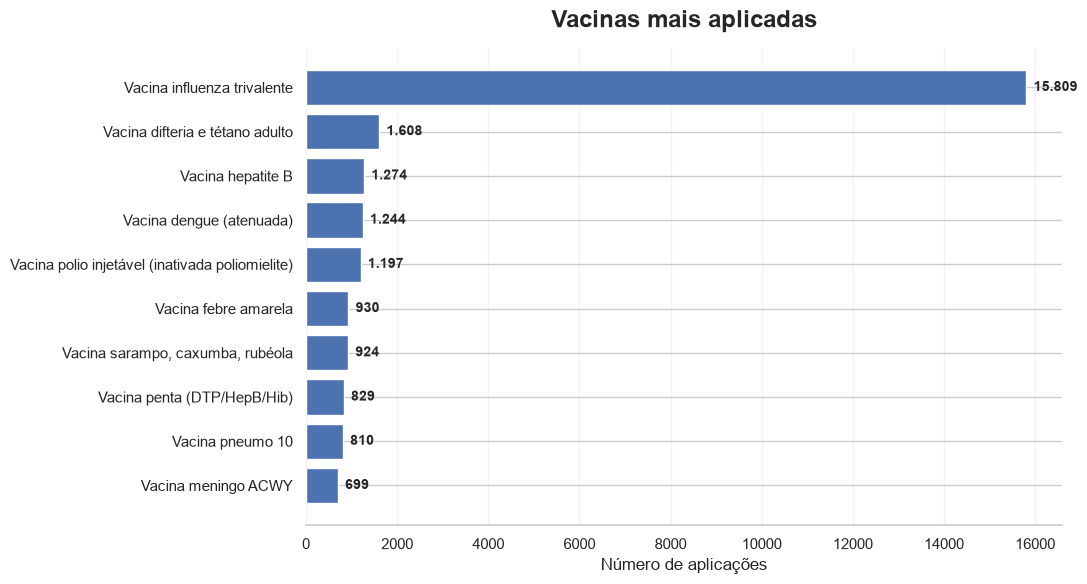

In [7]:
top_vacinas = vacinas.head(10).sort_values("Aplicações")

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    top_vacinas["Vacina"].astype(str),
    top_vacinas["Aplicações"]
)

ax.set_title("Vacinas mais aplicadas", fontsize=17, fontweight="bold", pad=15)
ax.set_xlabel("Número de aplicações")
ax.set_ylabel("")

for bar, valor in zip(bars, top_vacinas["Aplicações"]):
    ax.text(
        bar.get_width() + top_vacinas["Aplicações"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 8. Participação percentual dos imunizantes

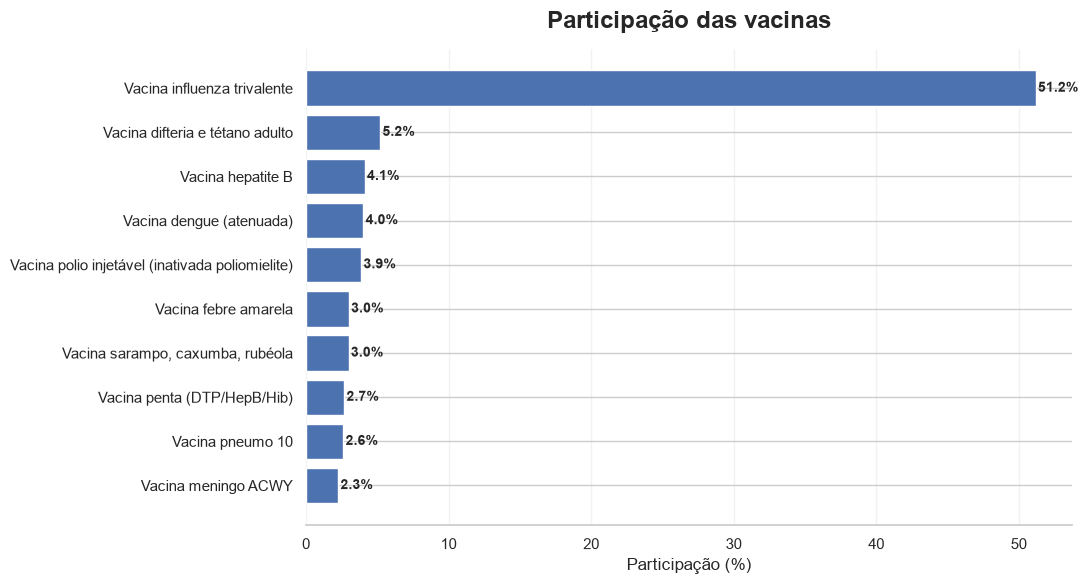

In [8]:
top_percentual = vacinas.head(10).sort_values("Percentual (%)")

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    top_percentual["Vacina"].astype(str),
    top_percentual["Percentual (%)"]
)

ax.set_title("Participação das vacinas", fontsize=17, fontweight="bold", pad=15)
ax.set_xlabel("Participação (%)")
ax.set_ylabel("")

for bar, valor in zip(bars, top_percentual["Percentual (%)"]):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:.1f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 9. Concentração das aplicações

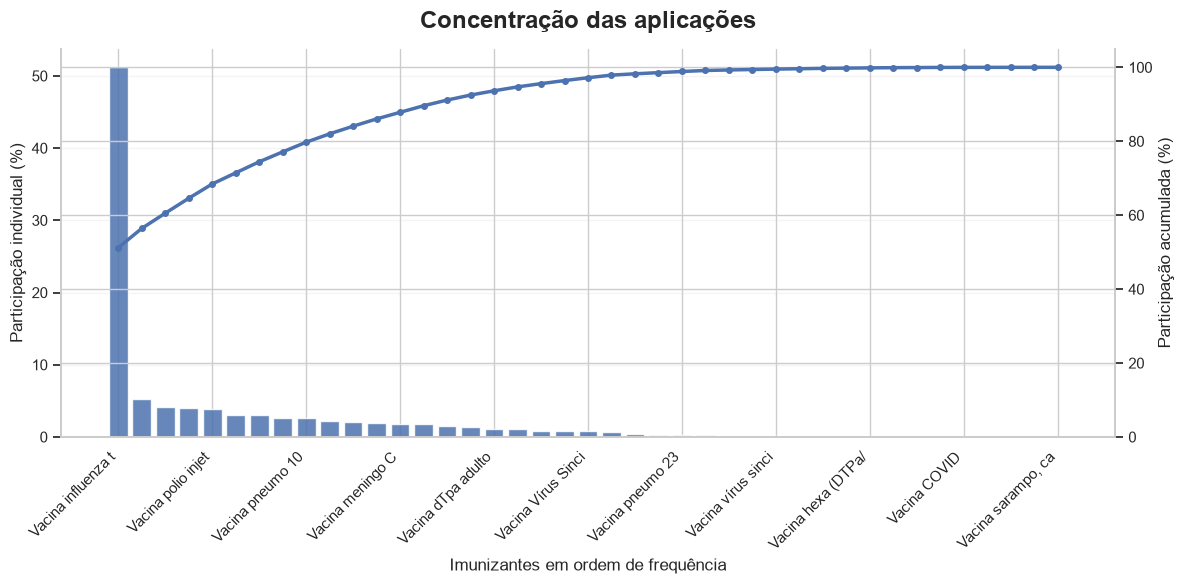

Os 5 imunizantes mais frequentes representam 68.4% dos registros.
Os 10 imunizantes mais frequentes representam 82.0% dos registros.


In [9]:
pareto = vacinas.copy()
pareto["Acumulado (%)"] = pareto["Percentual (%)"].cumsum()

x = np.arange(len(pareto))

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    x,
    pareto["Percentual (%)"],
    alpha=0.85
)

ax1.set_xlabel("Imunizantes em ordem de frequência")
ax1.set_ylabel("Participação individual (%)")
ax1.set_title(
    "Concentração das aplicações",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax2 = ax1.twinx()

ax2.plot(
    x,
    pareto["Acumulado (%)"],
    marker="o",
    linewidth=2.5,
    markersize=4
)

ax2.set_ylabel("Participação acumulada (%)")
ax2.set_ylim(0, 105)

n = len(pareto)
passo = max(1, n // 10)
indices = list(range(0, n, passo))

ax1.set_xticks(indices)
ax1.set_xticklabels(
    [str(pareto.iloc[i]["Vacina"])[:18] for i in indices],
    rotation=45,
    ha="right"
)

ax1.grid(axis="y", alpha=0.2)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Os 5 imunizantes mais frequentes representam {pareto.head(5)['Percentual (%)'].sum():.1f}% dos registros.")
print(f"Os 10 imunizantes mais frequentes representam {pareto.head(10)['Percentual (%)'].sum():.1f}% dos registros.")

## 10. Distribuição por estratégia

,Estratégia,Aplicações,Percentual (%)
0,Rotina,22646,73.328368
1,Especial,7791,25.227471
2,Pós-exposição,239,0.773889
3,Intensificação,168,0.543989
4,Pré-exposição,10,0.032380
5,Vacinação Escolar,6,0.019428
6,Pós,6,0.019428
7,Campanha indiscriminada,5,0.016190
8,19,5,0.016190
9,Monitoramento das Estratégias de Vacinação,4,0.012952


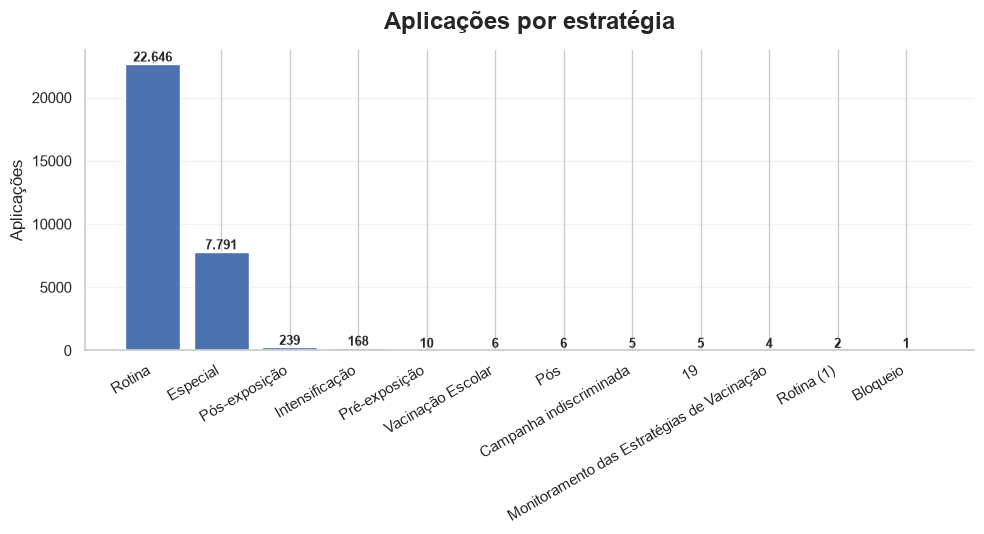

In [10]:
estrategias = (
    df["estrategia"]
    .value_counts(dropna=False)
    .rename_axis("Estratégia")
    .reset_index(name="Aplicações")
)

estrategias["Percentual (%)"] = estrategias["Aplicações"] / len(df) * 100

display(estrategias)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    estrategias["Estratégia"].astype(str),
    estrategias["Aplicações"]
)

ax.set_title("Aplicações por estratégia", fontsize=17, fontweight="bold", pad=15)
ax.set_ylabel("Aplicações")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")

for bar, valor in zip(bars, estrategias["Aplicações"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{valor:,}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 11. Vacina por estratégia

In [11]:
tabela_vacina_estrategia = pd.crosstab(
    df["nome_da_vacina"],
    df["estrategia"]
)

display(tabela_vacina_estrategia.head(15))

estrategia,19,Bloqueio,Campanha indiscriminada,Especial,Intensificação,Monitoramento das Estratégias de Vacinação,Pré-exposição,Pós,Pós-exposição,Rotina,Rotina (1),Vacinação Escolar
nome_da_vacina,,,,,,,,,,,,
"NIRSEVIMABE 0,5ml",0,0,0,84,0,0,0,0,0,0,0,0
"NIRSEVIMABE 1,0ml",0,0,0,21,0,0,0,0,0,0,0,0
Vacina BCG,0,0,0,0,0,0,0,0,0,217,0,0
Vacina COVID,5,0,0,0,0,0,0,0,0,0,0,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",0,0,0,61,0,0,0,0,0,357,1,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de",0,0,0,0,0,0,0,0,0,1,0,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos",0,0,0,1,0,0,0,0,0,327,0,0
Vacina DTP,0,0,0,0,0,0,0,0,0,547,0,0
Vacina DTPa infantil,0,0,0,1,0,0,0,0,0,0,0,0


## 12. Mapa de calor

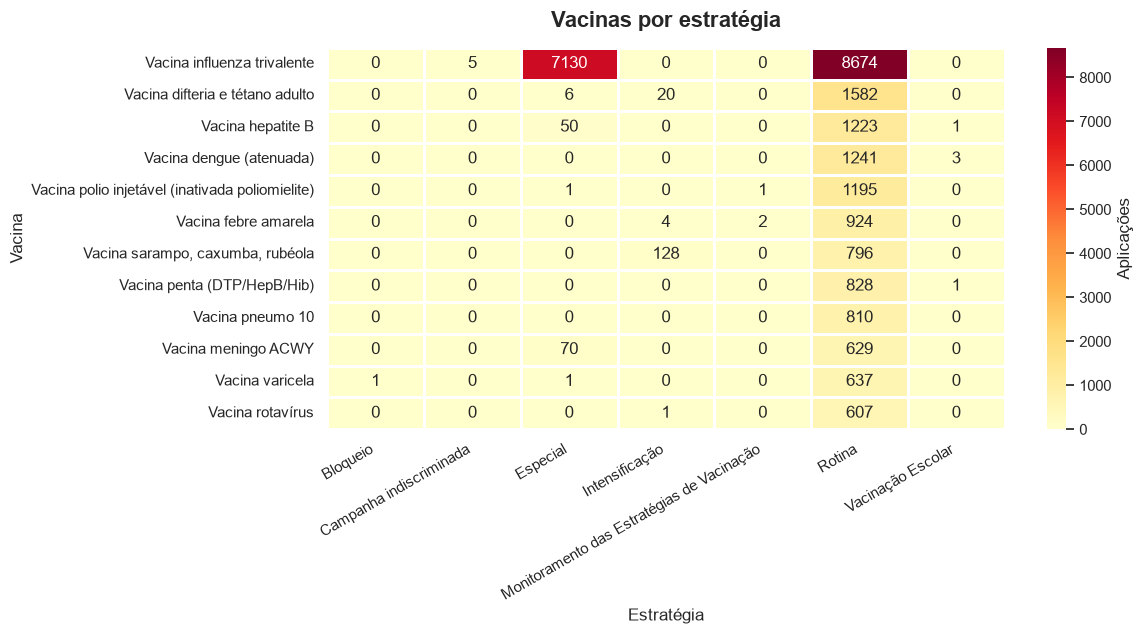

In [12]:
heatmap = pd.crosstab(
    df["nome_da_vacina"],
    df["estrategia"]
)

top_nomes = vacinas.head(12)["Vacina"].tolist()

heatmap = heatmap.reindex(
    index=[vacina for vacina in top_nomes if vacina in heatmap.index],
    fill_value=0
)

heatmap = heatmap.loc[
    heatmap.sum(axis=1) > 0,
    heatmap.sum(axis=0) > 0
]

if heatmap.empty:
    print("Não há dados suficientes para gerar o mapa de calor.")
else:
    fig, ax = plt.subplots(figsize=(12, 6.5))

    sns.heatmap(
        heatmap,
        annot=True,
        fmt=".0f",
        cmap="YlOrRd",
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"label": "Aplicações"},
        ax=ax
    )

    ax.set_title("Vacinas por estratégia", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Estratégia")
    ax.set_ylabel("Vacina")

    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 13. Evolução mensal

In [13]:
principais = vacinas.head(5)["Vacina"]

mensal = (
    df[df["nome_da_vacina"].isin(principais)]
    .groupby(["mes", "nome_da_vacina"])
    .size()
    .unstack(fill_value=0)
)

display(mensal)

nome_da_vacina,Vacina dengue (atenuada),Vacina difteria e tétano adulto,Vacina hepatite B,Vacina influenza trivalente,Vacina polio injetável (inativada poliomielite)
mes,,,,,
2026-02,175,177,97,0,153
2026-03,321,330,303,1805,298
2026-04,239,405,339,5523,239
2026-05,267,335,272,4592,246
2026-06,242,314,237,3102,261


## 14. Gráfico da evolução mensal

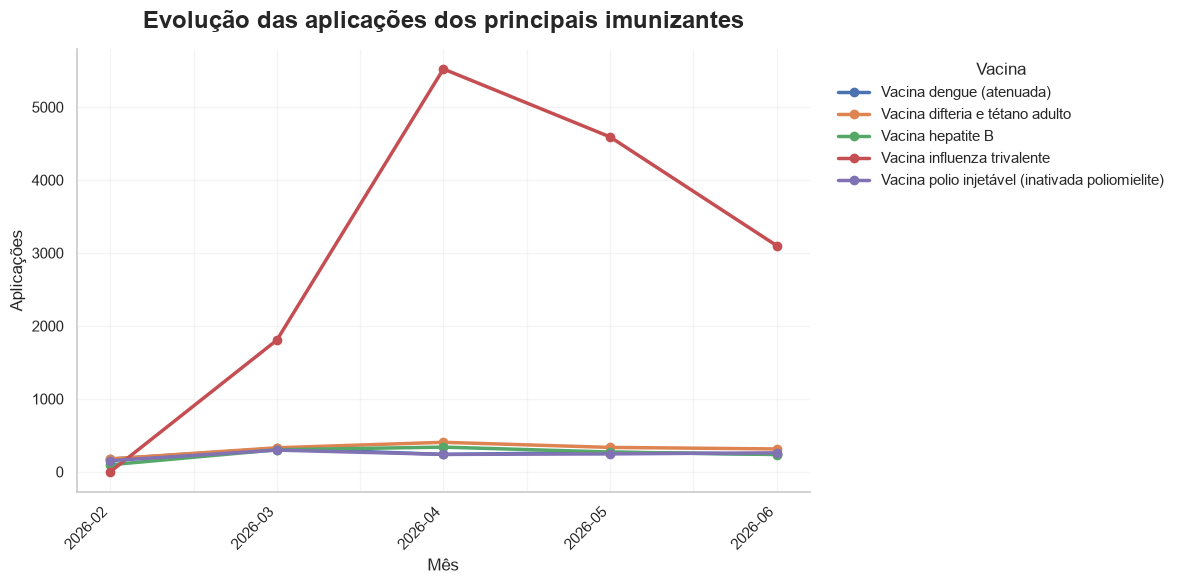

In [14]:
if mensal.empty:
    print("Não há registros suficientes para gerar a evolução mensal.")
else:
    ax = mensal.plot(
        figsize=(12, 6),
        marker="o",
        linewidth=2.5,
        markersize=6
    )

    ax.set_title(
        "Evolução das aplicações dos principais imunizantes",
        fontsize=17,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Mês")
    ax.set_ylabel("Aplicações")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.2)

    plt.xticks(rotation=45, ha="right")
    plt.legend(
        title="Vacina",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )

    plt.tight_layout()
    plt.show()

## 15. Mudança de posição das vacinas ao longo do tempo

In [15]:
ranking_mensal = (
    df.dropna(subset=["mes"])
    .groupby(["mes", "nome_da_vacina"])
    .size()
    .reset_index(name="Aplicações")
)

ranking_mensal["Posição"] = (
    ranking_mensal
    .groupby("mes")["Aplicações"]
    .rank(method="min", ascending=False)
    .astype(int)
)

display(
    ranking_mensal
    .sort_values(["mes", "Posição"])
    .head(30)
)

variacao_posicao = (
    ranking_mensal
    .groupby("nome_da_vacina")["Posição"]
    .agg(
        Posição_mínima="min",
        Posição_máxima="max",
        Posições_diferentes="nunique"
    )
    .sort_values(
        ["Posições_diferentes", "Posição_mínima"],
        ascending=[False, True]
    )
)

display(variacao_posicao.head(15))

,mes,nome_da_vacina,Aplicações,Posição
10,2026-02,Vacina difteria e tétano adulto,177,1
9,2026-02,Vacina dengue (atenuada),175,2
23,2026-02,Vacina polio injetável (inativada poliomielite),153,3
26,2026-02,"Vacina sarampo, caxumba, rubéola",125,4
27,2026-02,Vacina varicela,125,4
11,2026-02,Vacina febre amarela,122,6
18,2026-02,Vacina penta (DTP/HepB/Hib),108,7
14,2026-02,Vacina hepatite B,97,8
15,2026-02,Vacina meningo ACWY,85,9
2,2026-02,Vacina DTP,84,10


,Posição_mínima,Posição_máxima,Posições_diferentes
nome_da_vacina,,,
Vacina raiva em cultivo celular vero,17,23,5
Vacina pneumo 13,23,37,5
"Vacina vírus sincicial respiratório (recombinante, adjuvada)",25,31,5
Vacina hepatite B,3,8,4
"Vacina sarampo, caxumba, rubéola",4,10,4
Vacina varicela,4,16,4
Vacina pneumo 10,7,11,4
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",10,21,4
Vacina Vírus Sincicial A e B (recombinante),16,22,4


## 16. Distribuição anual

,ano,nome_da_vacina,Aplicações
16,2026.0,Vacina dengue (atenuada),1244
17,2026.0,Vacina difteria e tétano adulto,1561
21,2026.0,Vacina hepatite B,1248
23,2026.0,Vacina influenza trivalente,15022
32,2026.0,Vacina polio injetável (inativada poliomielite),1197


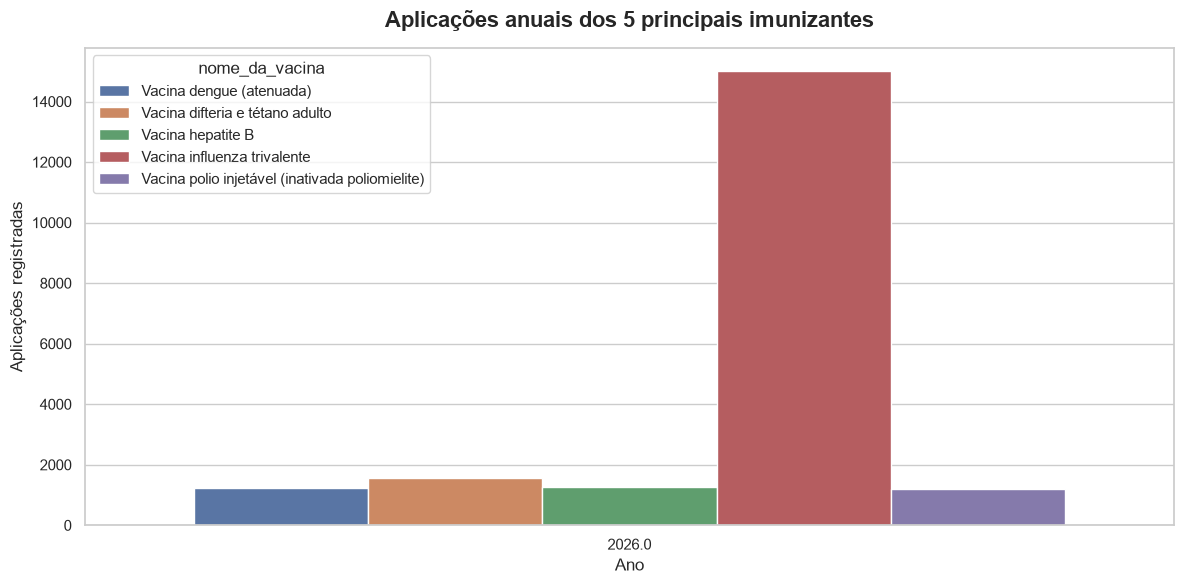

In [16]:
anual = (
    df.dropna(subset=["ano"])
    .groupby(["ano", "nome_da_vacina"])
    .size()
    .reset_index(name="Aplicações")
)

anual_top5 = anual[anual["nome_da_vacina"].isin(principais)]

display(anual_top5)

if anual_top5.empty:
    print("Não há dados anuais suficientes para gerar o gráfico.")
else:
    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=anual_top5,
        x="ano",
        y="Aplicações",
        hue="nome_da_vacina",
        ax=ax
    )

    ax.set_title(
        "Aplicações anuais dos 5 principais imunizantes",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Ano")
    ax.set_ylabel("Aplicações registradas")

    plt.tight_layout()
    plt.show()

## 17. Distribuição territorial por bairro

In [17]:
colunas_bairro = [
    coluna for coluna in df.columns
    if "bairro" in coluna.lower()
]

print("Colunas relacionadas a bairro:", colunas_bairro)

if not colunas_bairro:
    bairros = pd.DataFrame(columns=["Bairro", "Aplicações", "Percentual (%)"])
    print("A base não possui uma coluna de bairro.")
else:
    coluna_bairro = colunas_bairro[0]

    bairros = (
        df[coluna_bairro]
        .value_counts(dropna=False)
        .rename_axis("Bairro")
        .reset_index(name="Aplicações")
    )

    bairros["Percentual (%)"] = bairros["Aplicações"] / len(df) * 100

    display(bairros.head(15))

Colunas relacionadas a bairro: ['nome_do_bairro']


,Bairro,Aplicações,Percentual (%)
0,Mato Alto Lagoão,4735,15.332060
1,Bom Pastor,4064,13.159343
2,Polícia Rodoviária,3290,10.653110
3,Coloninha,3012,9.752939
4,Jardim Cibele,2317,7.502509
5,Vila São José,2131,6.900236
6,Cidade Alta,1973,6.388628
7,Divineia,1874,6.068063
8,Jardim das Avenidas,1788,5.789593
9,Arapongas,1414,4.578571


## 18. Principais bairros

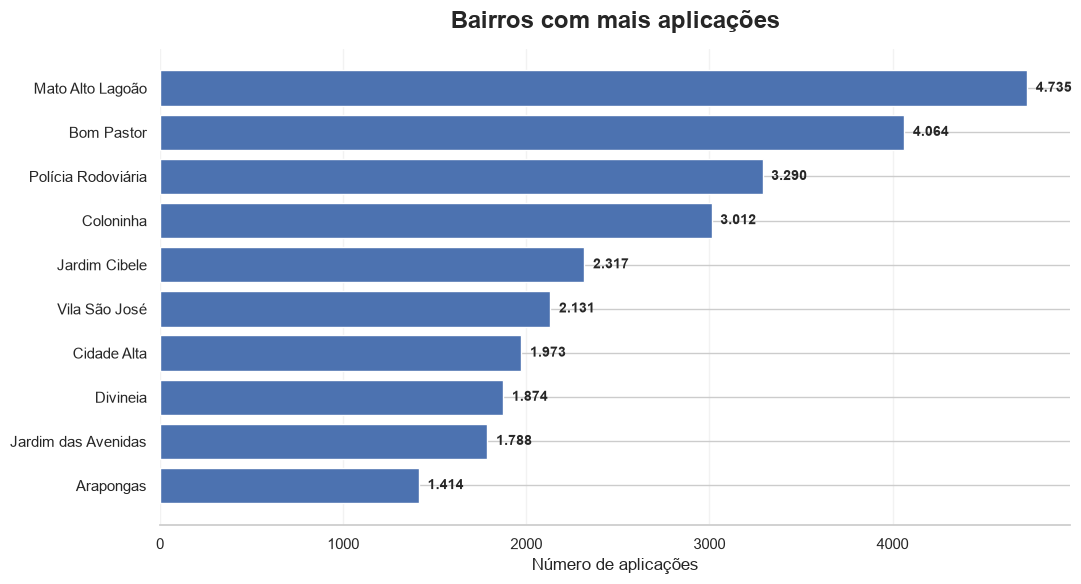

In [18]:
if bairros.empty:
    print("Não há dados de bairro para gerar o gráfico.")
else:
    top_bairros = bairros.head(10).sort_values("Aplicações")

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        top_bairros["Bairro"].astype(str),
        top_bairros["Aplicações"]
    )

    ax.set_title(
        "Bairros com mais aplicações",
        fontsize=17,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Número de aplicações")
    ax.set_ylabel("")

    for bar, valor in zip(bars, top_bairros["Aplicações"]):
        ax.text(
            bar.get_width() + top_bairros["Aplicações"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:,}".replace(",", "."),
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()

## 19. Distribuição por dose

In [19]:
doses = (
    df["dose"]
    .value_counts(dropna=False)
    .rename_axis("Dose")
    .reset_index(name="Aplicações")
)

doses["Percentual (%)"] = doses["Aplicações"] / len(df) * 100

display(doses.head(15))

,Dose,Aplicações,Percentual (%)
0,ÚNICA,17021,55.114464
1,1ª DOSE,4873,15.778907
2,2ª DOSE,3189,10.326069
3,REFORÇO,2178,7.052424
4,3ª DOSE,1287,4.167341
5,DOSE,1244,4.028106
6,2º REFORÇO,304,0.984360
7,1º REFORÇO,250,0.809507
8,REVACINAÇÃO,217,0.702652
9,PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMPOLA,101,0.327041


## 20. Principais doses

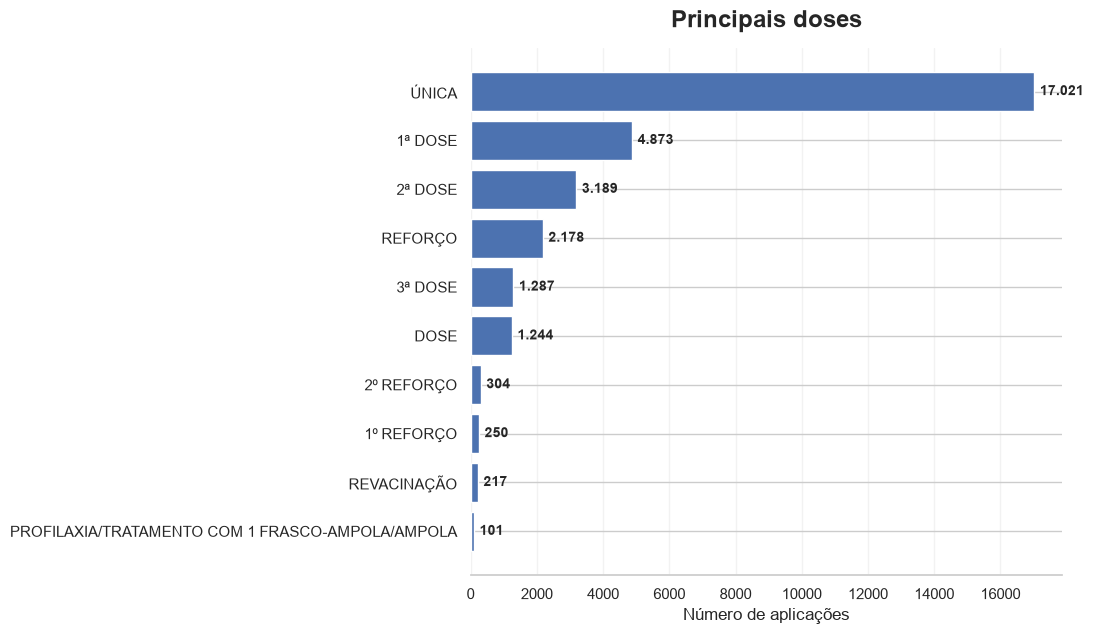

In [20]:
top_doses = doses.head(10).sort_values("Aplicações")

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.barh(
    top_doses["Dose"].astype(str),
    top_doses["Aplicações"]
)

ax.set_title(
    "Principais doses",
    fontsize=17,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Número de aplicações")
ax.set_ylabel("")

for bar, valor in zip(bars, top_doses["Aplicações"]):
    ax.text(
        bar.get_width() + top_doses["Aplicações"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 21. Combinação entre vacina, estratégia e dose

In [21]:
combinacoes = (
    df.groupby(
        ["nome_da_vacina", "estrategia", "dose"],
        dropna=False
    )
    .size()
    .reset_index(name="Aplicações")
    .sort_values("Aplicações", ascending=False)
)

combinacoes["Percentual (%)"] = (
    combinacoes["Aplicações"] / len(df) * 100
)

display(combinacoes.head(20))

,nome_da_vacina,estrategia,dose,Aplicações,Percentual (%)
102,Vacina influenza trivalente,Rotina,ÚNICA,8019,25.965742
99,Vacina influenza trivalente,Especial,ÚNICA,7073,22.902568
47,Vacina dengue (atenuada),Rotina,1ª DOSE,1014,3.283360
60,Vacina difteria e tétano adulto,Rotina,REFORÇO,817,2.645468
84,Vacina hepatite B,Rotina,1ª DOSE,513,1.661108
100,Vacina influenza trivalente,Rotina,1ª DOSE,473,1.531587
26,Vacina HPV quadrivalente,Rotina,ÚNICA,396,1.282259
147,Vacina polio injetável (inativada poliomielite),Rotina,REFORÇO,356,1.152738
176,Vacina varicela,Rotina,2ª DOSE,354,1.146262
165,"Vacina sarampo, caxumba, rubéola",Rotina,1ª DOSE,351,1.136548


## 22. Vacina, estratégia e dose ao longo do tempo

In [22]:
combinacoes_mensais = (
    df.dropna(subset=["mes"])
    .groupby(
        ["mes", "nome_da_vacina", "estrategia", "dose"],
        dropna=False
    )
    .size()
    .reset_index(name="Aplicações")
    .sort_values(["mes", "Aplicações"], ascending=[True, False])
)

display(combinacoes_mensais.head(30))

,mes,nome_da_vacina,estrategia,dose,Aplicações
14,2026-02,Vacina dengue (atenuada),Rotina,1ª DOSE,174
20,2026-02,Vacina difteria e tétano adulto,Rotina,REFORÇO,98
77,2026-02,Vacina varicela,Rotina,2ª DOSE,81
5,2026-02,Vacina HPV quadrivalente,Rotina,ÚNICA,63
21,2026-02,Vacina febre amarela,Rotina,DOSE,50
61,2026-02,Vacina polio injetável (inativada poliomielite),Rotina,REFORÇO,48
74,2026-02,"Vacina sarampo, caxumba, rubéola",Rotina,2ª DOSE,48
3,2026-02,Vacina DTP,Rotina,2º REFORÇO,47
25,2026-02,Vacina hepatite A infantil,Rotina,ÚNICA,44
68,2026-02,Vacina rotavírus,Rotina,1ª DOSE,44


## 23. Conferência de códigos e nomes das vacinas

In [23]:
if "codigo_da_vacina" not in df.columns:
    print("A coluna codigo_da_vacina não está disponível na base.")
else:
    codigos_vacinas = (
        df[["codigo_da_vacina", "nome_da_vacina"]]
        .drop_duplicates()
        .sort_values(["codigo_da_vacina", "nome_da_vacina"])
    )

    display(codigos_vacinas)

    conflitos = (
        codigos_vacinas
        .groupby("codigo_da_vacina")["nome_da_vacina"]
        .nunique()
        .loc[lambda serie: serie > 1]
    )

    print("Códigos associados a mais de um nome:", len(conflitos))

    if len(conflitos) > 0:
        display(
            codigos_vacinas[
                codigos_vacinas["codigo_da_vacina"].isin(conflitos.index)
            ]
        )

,codigo_da_vacina,nome_da_vacina
342,9,Vacina hepatite B
283,14,Vacina febre amarela
1519,15,Vacina BCG
1929,17,Vacina Hib
4913,21,Vacina pneumo 23
22275,22,Vacina polio injetável
1222,22,Vacina polio injetável (inativada poliomielite)
1325,24,"Vacina sarampo, caxumba, rubéola"
21750,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina..."
21751,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina..."


Códigos associados a mais de um nome: 7


,codigo_da_vacina,nome_da_vacina
22275,22,Vacina polio injetável
1222,22,Vacina polio injetável (inativada poliomielite)
1325,24,"Vacina sarampo, caxumba, rubéola"
21750,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina..."
21751,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina..."
22264,42,Vacina penta
1142,42,Vacina penta (DTP/HepB/Hib)
21867,87,Vacina COVID
0,87,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)"
21871,102,Vacina COVID


## 24. Preservação de apresentações próximas

In [24]:
termos = ["COVID", "NIRSEVIMABE"]

for termo in termos:
    encontrados = (
        df.loc[
            df["nome_da_vacina"]
            .astype("string")
            .str.contains(termo, case=False, na=False),
            "nome_da_vacina"
        ]
        .value_counts()
        .rename_axis("Vacina")
        .reset_index(name="Aplicações")
    )

    print(f"Categorias contendo {termo}:")
    display(encontrados)

if "vacina_estrategia_e_dose" in df.columns:
    apresentacoes = (
        df["vacina_estrategia_e_dose"]
        .value_counts(dropna=False)
        .rename_axis("Vacina + estratégia + dose")
        .reset_index(name="Aplicações")
    )

    apresentacoes["Percentual (%)"] = (
        apresentacoes["Aplicações"] / len(df) * 100
    )

    display(apresentacoes.head(20))
else:
    print("A coluna vacina_estrategia_e_dose não está disponível na base.")

Categorias contendo COVID:


,Vacina,Aplicações
0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",419
1,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediá...",328
2,Vacina COVID,5
3,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediá...",1


Categorias contendo NIRSEVIMABE:


,Vacina,Aplicações
0,"NIRSEVIMABE 0,5ml",84
1,"NIRSEVIMABE 1,0ml",21


,Vacina + estratégia + dose,Aplicações,Percentual (%)
0,Vacina influenza trivalente (33) - Rotina (1) ...,8019,25.965742
1,Vacina influenza trivalente (33) - Especial (2...,7073,22.902568
2,Vacina dengue (atenuada) (104) - Rotina (1) - ...,1026,3.322216
3,Vacina difteria e tétano adulto (25) - Rotina ...,817,2.645468
4,Vacina hepatite B (9) - Rotina (1) - 1ª DOSE (1),513,1.661108
5,Vacina influenza trivalente (33) - Rotina (1) ...,473,1.531587
6,Vacina HPV quadrivalente (67) - Rotina (1) - Ú...,396,1.282259
7,Vacina polio injetável (inativada poliomielite...,365,1.181880
8,Vacina varicela (34) - Rotina (1) - 2ª DOSE (2),354,1.146262
9,"Vacina sarampo, caxumba, rubéola (24) - Rotina...",349,1.130072


## 25. Comparação entre imunizantes por diferentes recortes

In [25]:
top12 = vacinas.head(12)["Vacina"]

recorte_estrategia = (
    df[df["nome_da_vacina"].isin(top12)]
    .groupby(["nome_da_vacina", "estrategia"])
    .size()
    .reset_index(name="Aplicações")
)

recorte_estrategia["Percentual dentro da vacina (%)"] = (
    recorte_estrategia["Aplicações"]
    / recorte_estrategia.groupby("nome_da_vacina")["Aplicações"].transform("sum")
    * 100
)

display(
    recorte_estrategia
    .sort_values(["nome_da_vacina", "Aplicações"], ascending=[True, False])
)

,nome_da_vacina,estrategia,Aplicações,Percentual dentro da vacina (%)
0,Vacina dengue (atenuada),Rotina,1241,99.758842
1,Vacina dengue (atenuada),Vacinação Escolar,3,0.241158
4,Vacina difteria e tétano adulto,Rotina,1582,98.383085
3,Vacina difteria e tétano adulto,Intensificação,20,1.243781
2,Vacina difteria e tétano adulto,Especial,6,0.373134
7,Vacina febre amarela,Rotina,924,99.354839
5,Vacina febre amarela,Intensificação,4,0.430108
6,Vacina febre amarela,Monitoramento das Estratégias de Vacinação,2,0.215054
9,Vacina hepatite B,Rotina,1223,95.996860
8,Vacina hepatite B,Especial,50,3.924647


## 26. Aplicações e pessoas

In [26]:
possiveis_identificadores = [
    coluna for coluna in df.columns
    if any(
        termo in coluna.lower()
        for termo in ["cpf", "cns", "id_pessoa", "id_paciente", "paciente", "pessoa"]
    )
]

print("Possíveis identificadores de pessoa:", possiveis_identificadores)
print("Total de aplicações registradas:", len(df))

if possiveis_identificadores:
    identificador = possiveis_identificadores[0]
    print(
        f"Pessoas distintas segundo {identificador}:",
        df[identificador].nunique(dropna=True)
    )

Possíveis identificadores de pessoa: []
Total de aplicações registradas: 30883


## 27. Síntese dos resultados

In [27]:
total_aplicacoes = len(df)
quantidade_imunizantes = df["nome_da_vacina"].nunique()
quantidade_estrategias = df["estrategia"].nunique()
vacina_principal = vacinas.iloc[0]["Vacina"]
participacao_principal = vacinas.iloc[0]["Percentual (%)"]
participacao_top5 = vacinas.head(5)["Percentual (%)"].sum()
participacao_top10 = vacinas.head(10)["Percentual (%)"].sum()

print(f"Total de aplicações analisadas: {total_aplicacoes:,}".replace(",", "."))
print(f"Quantidade de imunizantes: {quantidade_imunizantes}")
print(f"Quantidade de estratégias: {quantidade_estrategias}")
print(f"Imunizante mais frequente: {vacina_principal}")
print(f"Participação do imunizante mais frequente: {participacao_principal:.1f}%")
print(f"Participação acumulada dos 5 principais imunizantes: {participacao_top5:.1f}%")
print(f"Participação acumulada dos 10 principais imunizantes: {participacao_top10:.1f}%")

if not bairros.empty:
    print(f"Quantidade de bairros: {df[coluna_bairro].nunique(dropna=True)}")
else:
    print("Quantidade de bairros: não disponível")

print(f"Período analisado: {df['data_da_aplicacao'].min()} até {df['data_da_aplicacao'].max()}")

Total de aplicações analisadas: 30.883
Quantidade de imunizantes: 41
Quantidade de estratégias: 12
Imunizante mais frequente: Vacina influenza trivalente
Participação do imunizante mais frequente: 51.2%
Participação acumulada dos 5 principais imunizantes: 68.4%
Participação acumulada dos 10 principais imunizantes: 82.0%
Quantidade de bairros: 15
Período analisado: 2026-02-01 00:00:00 até 2026-06-30 00:00:00


## 28. Respostas às perguntas orientadoras

In [28]:
print("1. Quais vacinas mais se destacam e por quais medidas?")
display(
    vacinas.head(10)[["Vacina", "Aplicações", "Percentual (%)"]]
)

print("2. A posição das vacinas muda conforme o período?")
display(
    variacao_posicao.head(10)
)

print("3. A base se concentra em poucos imunizantes ou se distribui de forma mais equilibrada?")
print(f"Os 5 primeiros imunizantes representam {participacao_top5:.1f}% dos registros.")
print(f"Os 10 primeiros imunizantes representam {participacao_top10:.1f}% dos registros.")

print("4. As apresentações próximas permanecem diferenciadas?")
if "vacina_estrategia_e_dose" in df.columns:
    print(f"Foram identificadas {len(apresentacoes)} combinações distintas de vacina, estratégia e dose.")
else:
    print("A coluna específica de combinação não está disponível; a diferenciação foi analisada pelas colunas individuais.")

print("5. Como estratégia e dose modificam a leitura da distribuição?")
display(
    recorte_estrategia
    .sort_values("Aplicações", ascending=False)
    .head(20)
)

1. Quais vacinas mais se destacam e por quais medidas?


,Vacina,Aplicações,Percentual (%)
0,Vacina influenza trivalente,15809,51.189975
1,Vacina difteria e tétano adulto,1608,5.206748
2,Vacina hepatite B,1274,4.125247
3,Vacina dengue (atenuada),1244,4.028106
4,Vacina polio injetável (inativada poliomielite),1197,3.875919
5,Vacina febre amarela,930,3.011365
6,"Vacina sarampo, caxumba, rubéola",924,2.991937
7,Vacina penta (DTP/HepB/Hib),829,2.684325
8,Vacina pneumo 10,810,2.622802
9,Vacina meningo ACWY,699,2.263381


2. A posição das vacinas muda conforme o período?


,Posição_mínima,Posição_máxima,Posições_diferentes
nome_da_vacina,,,
Vacina raiva em cultivo celular vero,17,23,5
Vacina pneumo 13,23,37,5
"Vacina vírus sincicial respiratório (recombinante, adjuvada)",25,31,5
Vacina hepatite B,3,8,4
"Vacina sarampo, caxumba, rubéola",4,10,4
Vacina varicela,4,16,4
Vacina pneumo 10,7,11,4
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",10,21,4
Vacina Vírus Sincicial A e B (recombinante),16,22,4


3. A base se concentra em poucos imunizantes ou se distribui de forma mais equilibrada?
Os 5 primeiros imunizantes representam 68.4% dos registros.
Os 10 primeiros imunizantes representam 82.0% dos registros.
4. As apresentações próximas permanecem diferenciadas?
Foram identificadas 163 combinações distintas de vacina, estratégia e dose.
5. Como estratégia e dose modificam a leitura da distribuição?


,nome_da_vacina,estrategia,Aplicações,Percentual dentro da vacina (%)
13,Vacina influenza trivalente,Rotina,8674,54.867481
12,Vacina influenza trivalente,Especial,7130,45.100892
4,Vacina difteria e tétano adulto,Rotina,1582,98.383085
0,Vacina dengue (atenuada),Rotina,1241,99.758842
9,Vacina hepatite B,Rotina,1223,95.996860
21,Vacina polio injetável (inativada poliomielite),Rotina,1195,99.832916
7,Vacina febre amarela,Rotina,924,99.354839
16,Vacina penta (DTP/HepB/Hib),Rotina,828,99.879373
18,Vacina pneumo 10,Rotina,810,100.000000
25,"Vacina sarampo, caxumba, rubéola",Rotina,796,86.147186


## 29. Limitações

- Os registros representam aplicações, não necessariamente pessoas únicas.
- A frequência de aplicações não representa, sozinha, cobertura vacinal.
- Os resultados dependem do período e da qualidade dos dados disponíveis.
- A análise descreve a distribuição dos registros e não mede eficácia clínica dos imunizantes.
- Bairro e sala de vacinação não são considerados equivalentes.
- Quando uma variável específica não está presente na base, a análise correspondente não é inventada ou substituída por outra variável.

## Conclusão

A análise exploratória permite identificar quais imunizantes possuem maior presença na base, comparar sua participação por diferentes medidas e observar como os registros se distribuem segundo período, estratégia, dose e território.

O ranking mostra os imunizantes com maior volume de aplicações, enquanto a participação percentual e a curva acumulada permitem avaliar a concentração dos registros. A análise temporal verifica mudanças na posição relativa das vacinas, e os cruzamentos com estratégia e dose preservam diferenças importantes entre os registros.

As apresentações próximas também são mantidas separadas quando a base fornece essa informação, evitando agrupamentos inadequados. Dessa forma, os resultados permanecem baseados nas dimensões efetivamente disponíveis no arquivo `vacinas_analitico.csv`.